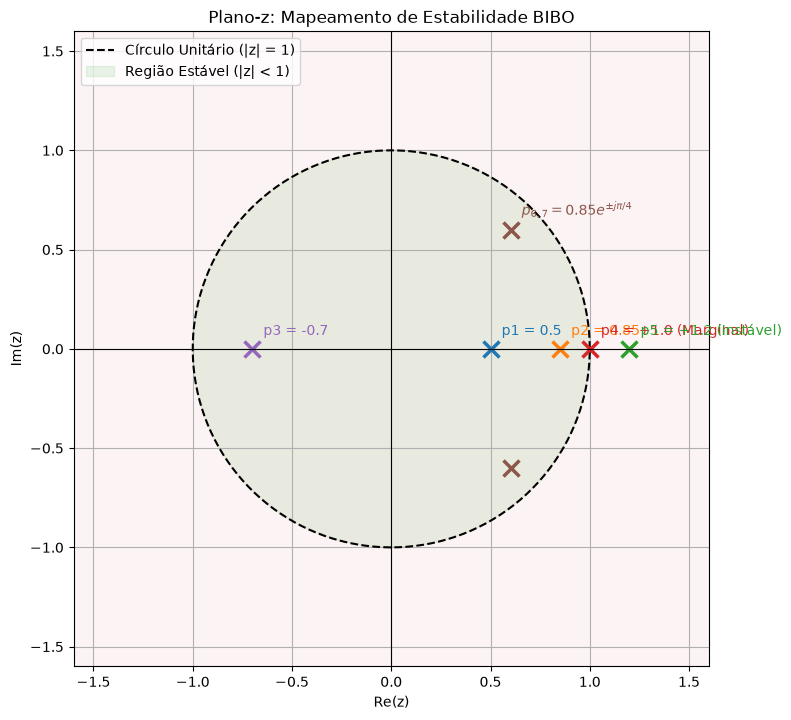

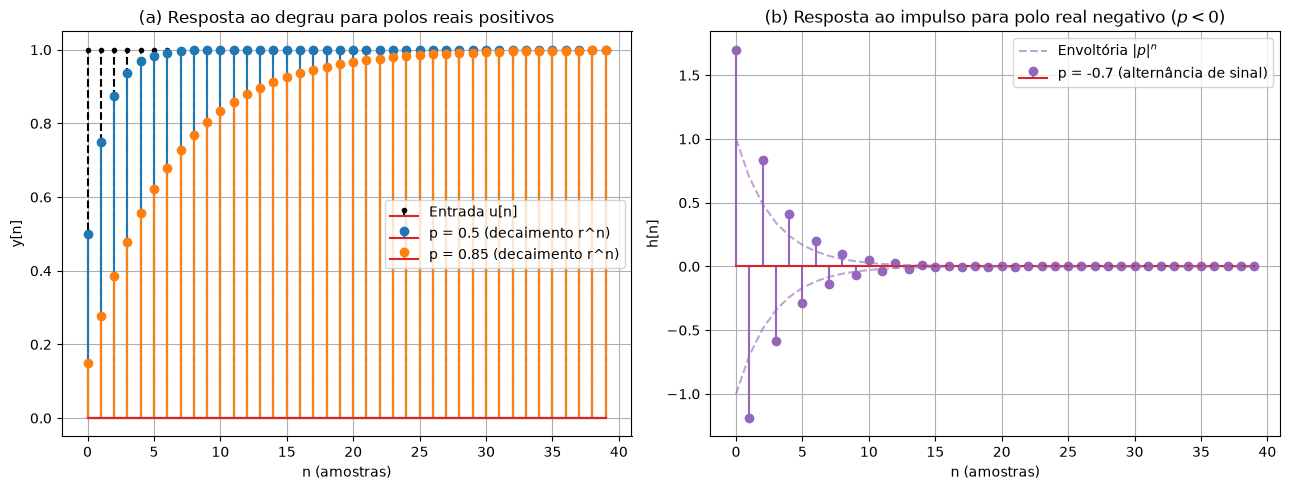

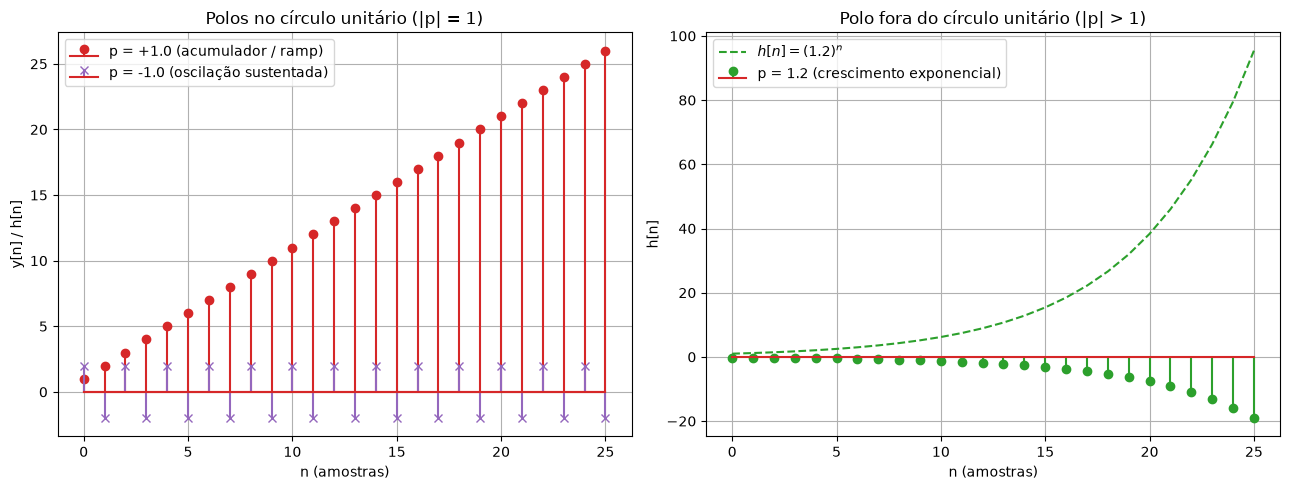

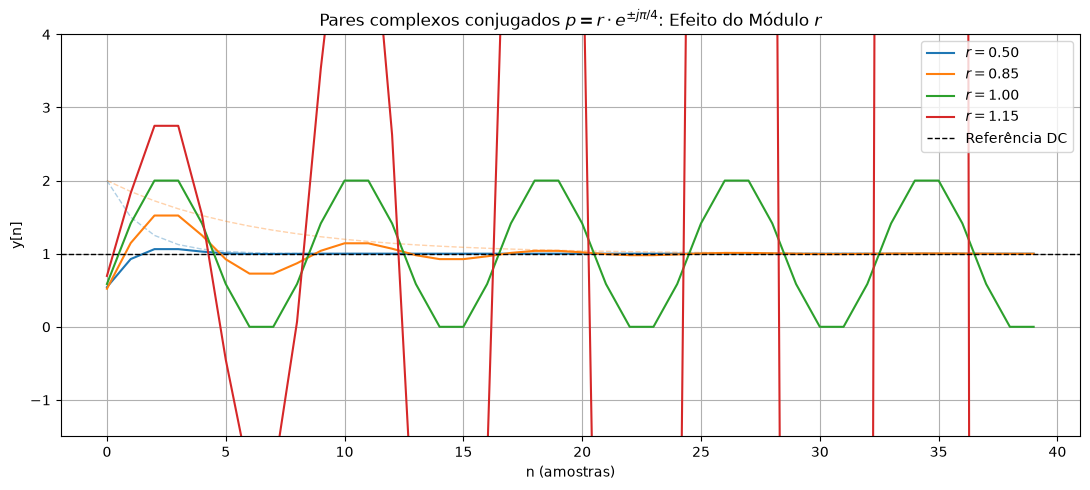

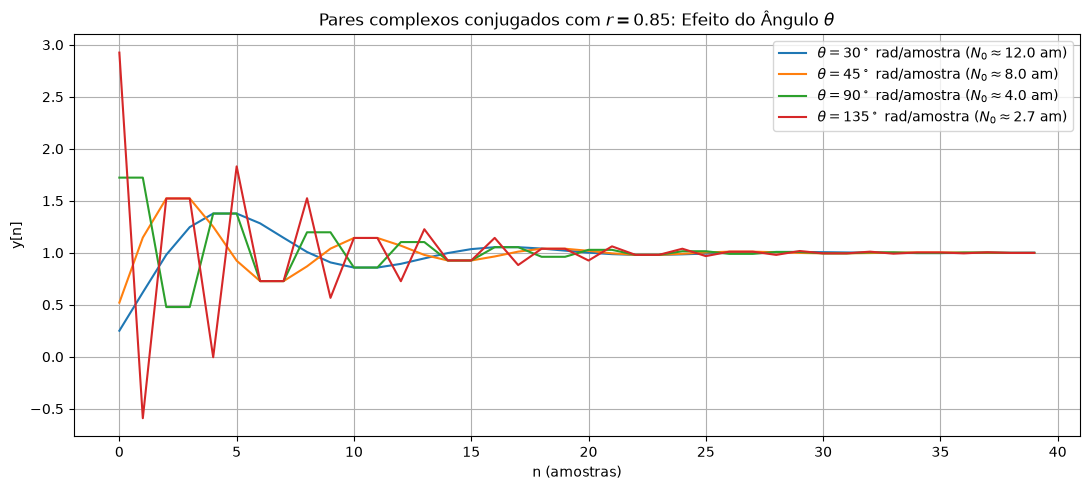

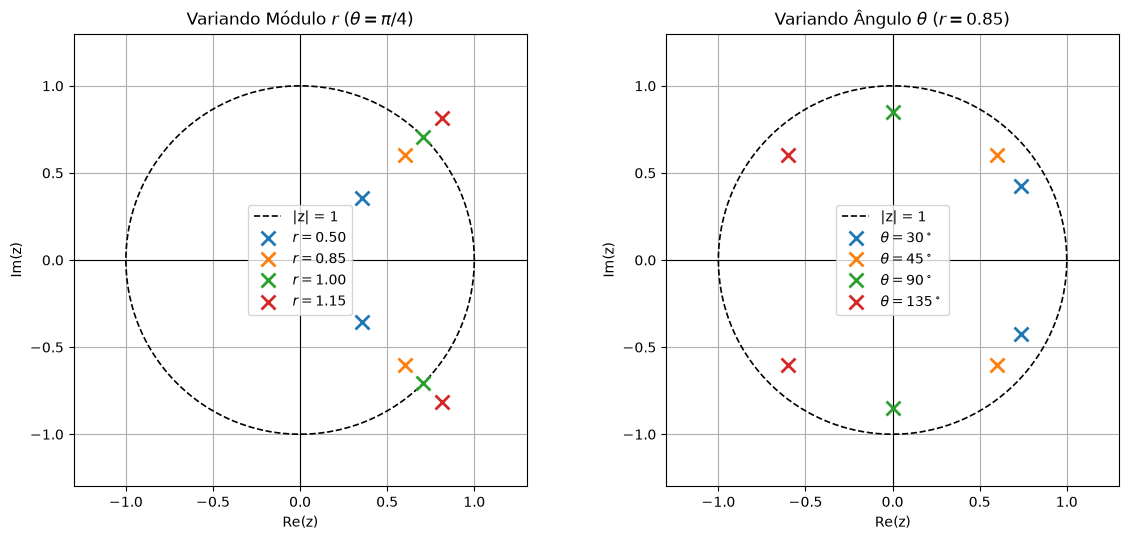

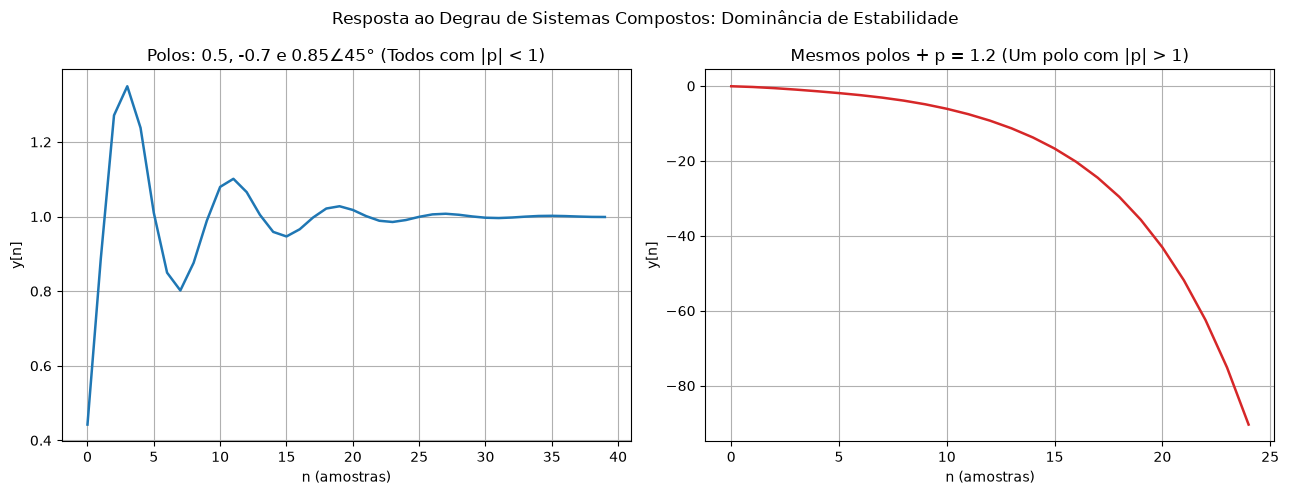

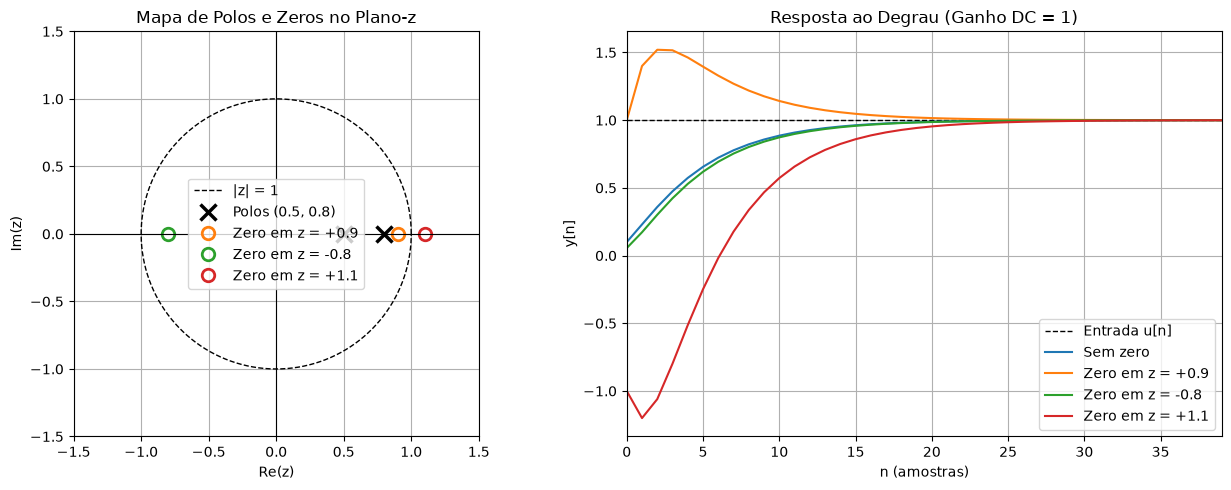

ANÁLISE DE ESTABILIDADE NO PLANO-Z (CRITÉRIO |p_k| < 1)
Sistema                  Polos                                 Estabilidade      |p_max|      y[N-1]  Ts (amostras)
p1 = 0.5                 +0.50                                 ESTÁVEL            0.5000           1              5
p2 = 0.85                +0.85                                 ESTÁVEL            0.8500           1             24
p3 = -0.7                -0.70                                 ESTÁVEL            0.7000           1             10
p4 = +1.0 (Marginal)     +1.00                                 MARGINAL           1.0000         120              -
p5 = +1.2 (Instável)     +1.20                                 INSTÁVEL           1.2000  -3.175e+09              -
par r=0.50, theta=pi/4   0.50∠45.0° (+0.35±0.35j)              ESTÁVEL            0.5000           1              5
par r=0.85, theta=pi/4   0.85∠45.0° (+0.60±0.60j)              ESTÁVEL            0.8500           1             24
par r=1.00, thet

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

# ============================================================
# 1. CONFIGURAÇÕES DA SIMULAÇÃO
# ============================================================

N_SAMPLES = 40  # Número de amostras (n = 0, 1, ..., N_SAMPLES-1)
n = np.arange(N_SAMPLES)

# Polos reais para estudo
P_REAL_ESTAVEL_1 = 0.5
P_REAL_ESTAVEL_2 = 0.85
P_REAL_NEGATIVO = -0.7
P_REAL_MARGINAL = 1.0
P_REAL_INSTAVEL = 1.2

# Estudo de pares complexos conjugados: p = r * exp(± j * theta)
R_REF = 0.85
THETA_REF = np.pi / 4  # 45 graus (0.7854 rad)

# Variação do módulo r com theta fixo (theta = pi/4)
THETA_FIXO = np.pi / 4
lista_r = [0.5, 0.85, 1.0, 1.15]

# Variação do ângulo theta com r fixo (r = 0.85)
R_FIXO = 0.85
lista_theta = [np.pi / 6, np.pi / 4, np.pi / 2, 3 * np.pi / 4]

# Zeros para análise do efeito no plano-z (polos base em 0.5 e 0.8)
polos_base = [0.5, 0.8]
lista_zeros = [None, 0.9, -0.8, 1.1]


# ============================================================
# 2. MODELAGEM MATEMÁTICA MANUAL (DOMÍNIO Z E RESÍDUOS)
# ============================================================


def par_complexo_z(r, theta):
  """Retorna par complexo conjugado no plano-z: p = r * exp(± j * theta)"""
  return [
      complex(r * np.cos(theta), r * np.sin(theta)),
      complex(r * np.cos(theta), -r * np.sin(theta)),
  ]


def construir_sistema_z(polos, zeros=(), K=None):
  """Monta H(z) = K * prod(1 - z_k * z^-1) / prod(1 - p_k * z^-1).

  Retorna os coeficientes b (numerador) e a (denominador) em potências de z^-1.
  Se K não for informado, ajusta para ganho DC unitário H(1) = 1.
  """
  polos = np.array(polos, dtype=complex)
  zeros = np.array(zeros, dtype=complex)

  # Coeficientes em potências decrescentes de z
  den_z = np.real(np.poly(polos))
  num_z = np.real(np.poly(zeros)) if len(zeros) > 0 else np.array([1.0])

  if K is None:
    # Ajuste de ganho DC: H(1) = N(1) / D(1) = 1 => K = D(1) / N(1)
    val_den_1 = np.sum(den_z)
    val_num_1 = np.sum(num_z)
    if abs(val_num_1) > 1e-12 and abs(val_den_1) > 1e-12:
      K = val_den_1 / val_num_1
    else:
      K = 1.0

  b = K * num_z
  a = den_z

  return b, a


def residuos_z(b, a):
  """Expansão em frações parciais no domínio Z para H(z) = B(z)/A(z):

  r_k = N(p_k) / (p_k * D'(p_k)) em potências de z
  """
  polos = np.roots(a)
  N_grau = len(a) - 1
  M_grau = len(b) - 1

  # Alinha os coeficientes em potências de z
  num_z = np.zeros(N_grau + 1, dtype=complex)
  num_z[: M_grau + 1] = b

  den_z = np.array(a, dtype=complex)
  den_der = np.polyder(den_z)

  r = np.zeros(len(polos), dtype=complex)
  for i, pk in enumerate(polos):
    if abs(pk) > 1e-12:
      r[i] = np.polyval(num_z, pk) / (pk * np.polyval(den_der, pk))
    else:
      r[i] = 0.0

  return polos, r


def resposta_impulso_analitica(n_eixo, b, a):
  """Resposta ao impulso h[n] analítica via transformada z inversa:

  h[n] = sum( r_k * p_k^n ) u[n]
  """
  polos, r = residuos_z(b, a)
  h = np.zeros(len(n_eixo), dtype=complex)

  for i, pk in enumerate(polos):
    h += r[i] * (pk**n_eixo)

  h_real = np.real(h)
  if len(b) == len(a):
    h_real[0] = b[0] / a[0]

  return h_real


def resposta_degrau_analitica(n_eixo, b, a):
  """Resposta ao degrau analítica por acumulação da resposta ao impulso."""
  h = resposta_impulso_analitica(n_eixo, b, a)
  return np.cumsum(h)


# ============================================================
# 3. SIMULAÇÃO NUMÉRICA TEMPORAL (EQUAÇÃO DE DIFERENÇAS MANUAL)
# ============================================================


def simular_equacao_diferencas(b, a, x):
  """Simula iterativamente a equação de diferenças no tempo discreto:

  a[0]*y[n] = sum_{m=0}^M b[m]*x[n-m] - sum_{k=1}^N a[k]*y[n-k]
  """
  b = np.array(b, dtype=float)
  a = np.array(a, dtype=float)
  N_samples = len(x)
  y = np.zeros(N_samples, dtype=float)

  M = len(b) - 1
  N = len(a) - 1

  for k_n in range(N_samples):
    soma_x = 0.0
    for m in range(M + 1):
      if k_n - m >= 0:
        soma_x += b[m] * x[k_n - m]

    soma_y = 0.0
    for k in range(1, N + 1):
      if k_n - k >= 0:
        soma_y += a[k] * y[k_n - k]

    y[k_n] = (soma_x - soma_y) / a[0]

  return y


def degrau_discreto(polos, zeros=(), K=None):
  """Atalho: resposta ao degrau via equação de diferenças."""
  b, a = construir_sistema_z(polos, zeros, K)
  x = np.ones(len(n))
  return simular_equacao_diferencas(b, a, x)


def impulso_discreto(polos, zeros=(), K=None):
  """Atalho: resposta ao impulso via equação de diferenças."""
  b, a = construir_sistema_z(polos, zeros, K)
  x = np.zeros(len(n))
  x[0] = 1.0
  return simular_equacao_diferencas(b, a, x)


# ============================================================
# 4. ESTABILIDADE BIBO E MÉTRICAS NO PLANO-Z
# ============================================================


def classificar_estabilidade_z(polos, tol=1e-5):
  """Critério de Estabilidade BIBO no Plano-z:

  |p_k| < 1 para todo k  -> Assintoticamente / BIBO Estável
  algum |p_k| = 1        -> Marginalmente Estável
  algum |p_k| > 1        -> Instável
  """
  módulos = np.abs(np.array(polos, dtype=complex))

  if np.any(módulos > 1.0 + tol):
    return "INSTÁVEL"
  if np.any(np.abs(módulos - 1.0) <= tol):
    return "MARGINAL"
  return "ESTÁVEL"


def tempo_acomodacao_z(n_eixo, y, valor_final=1.0, tol=0.02):
  """Tempo de acomodação discreto (critério de 2%).

  Retorna a amostra n a partir da qual y[n] permanece dentro da faixa de tol.
  """
  if np.any(np.isinf(y)) or np.any(np.isnan(y)) or np.max(np.abs(y)) > 1e5:
    return np.nan

  fora = np.where(np.abs(y - valor_final) > tol * abs(valor_final))[0]

  if len(fora) == 0:
    return 0
  if fora[-1] + 1 >= len(n_eixo):
    return np.nan

  return n_eixo[fora[-1] + 1]


def texto_polos_z(polos):
  """Texto explicativo dos polos em coordenadas polares r*e^(j*theta) e cartesianas."""
  partes = []
  for p in np.array(polos, dtype=complex):
    r_val = np.abs(p)
    theta_val = np.angle(p)
    if abs(np.imag(p)) < 1e-6:
      partes.append(f"{p.real:+.2f}")
    elif np.imag(p) > 0:
      partes.append(
          f"{r_val:.2f}∠{np.degrees(theta_val):.1f}°"
          f" ({p.real:+.2f}±{np.imag(p):.2f}j)"
      )
  return ", ".join(partes)


# ============================================================
# 5. REPRESENTAÇÃO DOS POLOS NO PLANO-Z (CÍRCULO UNITÁRIO)
# ============================================================

fig, eixo = plt.subplots(figsize=(8, 8))

theta_circ = np.linspace(0, 2 * np.pi, 300)
eixo.plot(
    np.cos(theta_circ),
    np.sin(theta_circ),
    "k--",
    linewidth=1.5,
    label="Círculo Unitário (|z| = 1)",
)

circ_interno = plt.Circle(
    (0, 0),
    1.0,
    color="tab:green",
    alpha=0.10,
    label="Região Estável (|z| < 1)",
)
eixo.add_patch(circ_interno)
eixo.axvspan(-2, 2, color="tab:red", alpha=0.05)

pontos_z = [
    (P_REAL_ESTAVEL_1, 0, "p1 = 0.5", "C0"),
    (P_REAL_ESTAVEL_2, 0, "p2 = 0.85", "C1"),
    (P_REAL_NEGATIVO, 0, "p3 = -0.7", "C4"),
    (P_REAL_MARGINAL, 0, "p4 = +1.0 (Marginal)", "C3"),
    (P_REAL_INSTAVEL, 0, "p5 = +1.2 (Instável)", "C2"),
    (
        R_REF * np.cos(THETA_REF),
        R_REF * np.sin(THETA_REF),
        r"$p_{6,7} = 0.85 e^{\pm j\pi/4}$",
        "C5",
    ),
    (R_REF * np.cos(THETA_REF), -R_REF * np.sin(THETA_REF), None, "C5"),
]

for re, im, rotulo, cor in pontos_z:
  eixo.plot(re, im, "x", color=cor, markersize=12, markeredgewidth=2.5)
  if rotulo is not None:
    eixo.annotate(
        rotulo, (re, im), textcoords="offset points", xytext=(8, 10), color=cor
    )

eixo.axhline(0, color="k", linewidth=0.8)
eixo.axvline(0, color="k", linewidth=0.8)
eixo.set_xlim(-1.6, 1.6)
eixo.set_ylim(-1.6, 1.6)
eixo.set_aspect("equal", "box")

eixo.set_title("Plano-z: Mapeamento de Estabilidade BIBO")
eixo.set_xlabel(r"Re(z)")
eixo.set_ylabel(r"Im(z)")
eixo.legend(loc="upper left")
eixo.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 6. POLOS REAIS ESTÁVEIS: TAXA DE DECAIMENTO E ALTERNÂNCIA DE SINAL
# ============================================================

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))

eixos[0].stem(n, np.ones_like(n), linefmt="k--", markerfmt="k.", label="Entrada u[n]")
for polo, cor in [(P_REAL_ESTAVEL_1, "C0"), (P_REAL_ESTAVEL_2, "C1")]:
  y_deg = degrau_discreto([polo])
  eixos[0].stem(
      n,
      y_deg,
      linefmt=cor,
      markerfmt=cor + "o",
      label=f"p = {polo} (decaimento r^n)",
  )

eixos[0].set_title("(a) Resposta ao degrau para polos reais positivos")
eixos[0].set_xlabel("n (amostras)")
eixos[0].set_ylabel("y[n]")
eixos[0].legend()
eixos[0].grid(True)

y_neg = impulso_discreto([P_REAL_NEGATIVO])
eixos[1].stem(
    n,
    y_neg,
    linefmt="C4",
    markerfmt="C4o",
    label=f"p = {P_REAL_NEGATIVO} (alternância de sinal)",
)
eixos[1].plot(
    n, (abs(P_REAL_NEGATIVO)) ** n, "C4--", alpha=0.6, label=r"Envoltória $|p|^n$"
)
eixos[1].plot(n, -((abs(P_REAL_NEGATIVO)) ** n), "C4--", alpha=0.6)

eixos[1].set_title(r"(b) Resposta ao impulso para polo real negativo ($p < 0$)")
eixos[1].set_xlabel("n (amostras)")
eixos[1].set_ylabel("h[n]")
eixos[1].legend()
eixos[1].grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 7. POLOS MARGINAIS (|p| = 1) E INSTÁVEIS (|p| > 1)
# ============================================================

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))

n_curto = n[n <= 25]

y_marg_pos = degrau_discreto([P_REAL_MARGINAL])[: len(n_curto)]
y_marg_neg = impulso_discreto([-1.0])[: len(n_curto)]

eixos[0].stem(
    n_curto,
    y_marg_pos,
    linefmt="C3",
    markerfmt="C3o",
    label="p = +1.0 (acumulador / ramp)",
)
eixos[0].stem(
    n_curto,
    y_marg_neg,
    linefmt="C4",
    markerfmt="C4x",
    label="p = -1.0 (oscilação sustentada)",
)
eixos[0].set_title("Polos no círculo unitário (|p| = 1)")
eixos[0].set_xlabel("n (amostras)")
eixos[0].set_ylabel("y[n] / h[n]")
eixos[0].legend()
eixos[0].grid(True)

y_inst = impulso_discreto([P_REAL_INSTAVEL])[: len(n_curto)]
eixos[1].stem(
    n_curto,
    y_inst,
    linefmt="C2",
    markerfmt="C2o",
    label=f"p = {P_REAL_INSTAVEL} (crescimento exponencial)",
)
eixos[1].plot(
    n_curto, (P_REAL_INSTAVEL) ** n_curto, "C2--", label=r"$h[n] = (1.2)^n$"
)
eixos[1].set_title("Polo fora do círculo unitário (|p| > 1)")
eixos[1].set_xlabel("n (amostras)")
eixos[1].set_ylabel("h[n]")
eixos[1].legend()
eixos[1].grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 8. PARES COMPLEXOS: EFEITO DO MÓDULO (r)
# ============================================================

plt.figure(figsize=(11, 5))

for i, r_val in enumerate(lista_r):
  polos_c = par_complexo_z(r_val, THETA_FIXO)
  y_c = degrau_discreto(polos_c)

  plt.plot(n, y_c, color=f"C{i}", label=rf"$r = {r_val:.2f}$")

  if r_val < 1.0:
    plt.plot(n, 1.0 + (r_val**n), "--", color=f"C{i}", alpha=0.35, linewidth=1)

plt.axhline(1.0, color="k", linestyle="--", linewidth=1, label="Referência DC")
plt.title(
    r"Pares complexos conjugados $p = r \cdot e^{\pm j\pi/4}$: Efeito do Módulo"
    r" $r$"
)
plt.xlabel("n (amostras)")
plt.ylabel("y[n]")
plt.ylim(-1.5, 4.0)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 9. PARES COMPLEXOS: EFEITO DO ÂNGULO (THETA / FREQUÊNCIA DISCRETA)
# ============================================================

plt.figure(figsize=(11, 5))

for i, th_val in enumerate(lista_theta):
  polos_c = par_complexo_z(R_FIXO, th_val)
  y_c = degrau_discreto(polos_c)
  periodo_amostras = 2 * np.pi / th_val

  plt.plot(
      n,
      y_c,
      color=f"C{i}",
      label=(
          rf"$\theta = {np.degrees(th_val):.0f}^\circ$ rad/amostra ($N_0 \approx"
          rf" {periodo_amostras:.1f}$ am)"
      ),
  )

plt.title(
    r"Pares complexos conjugados com $r = 0.85$: Efeito do Ângulo $\theta$"
)
plt.xlabel("n (amostras)")
plt.ylabel("y[n]")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 10. MAPA DE POLOS DOS ESTUDOS COMPLEXOS NO PLANO-Z
# ============================================================

fig, eixos = plt.subplots(1, 2, figsize=(12, 5.5))

for ax in eixos:
  ax.plot(
      np.cos(theta_circ),
      np.sin(theta_circ),
      "k--",
      linewidth=1.2,
      label="|z| = 1",
  )
  ax.axhline(0, color="k", linewidth=0.8)
  ax.axvline(0, color="k", linewidth=0.8)
  ax.set_xlim(-1.3, 1.3)
  ax.set_ylim(-1.3, 1.3)
  ax.set_aspect("equal", "box")
  ax.set_xlabel("Re(z)")
  ax.set_ylabel("Im(z)")
  ax.grid(True)

for i, r_val in enumerate(lista_r):
  p = par_complexo_z(r_val, THETA_FIXO)
  eixos[0].plot(
      np.real(p),
      np.imag(p),
      "x",
      color=f"C{i}",
      markersize=10,
      markeredgewidth=2,
      label=rf"$r = {r_val:.2f}$",
  )
eixos[0].set_title(r"Variando Módulo $r$ ($\theta = \pi/4$)")
eixos[0].legend()

for i, th_val in enumerate(lista_theta):
  p = par_complexo_z(R_FIXO, th_val)
  eixos[1].plot(
      np.real(p),
      np.imag(p),
      "x",
      color=f"C{i}",
      markersize=10,
      markeredgewidth=2,
      label=rf"$\theta = {np.degrees(th_val):.0f}^\circ$",
  )
eixos[1].set_title(r"Variando Ângulo $\theta$ ($r = 0.85$)")
eixos[1].legend()

plt.tight_layout()
plt.show()


# ============================================================
# 11. SISTEMA COMPOSTO: DOMINÂNCIA DE POLOS NO PLANO-Z
# ============================================================

polos_compostos_estaveis = [0.5, -0.7] + par_complexo_z(R_REF, THETA_REF)
polos_compostos_instaveis = [0.5, -0.7, 1.2] + par_complexo_z(R_REF, THETA_REF)

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))

y_comp_est = degrau_discreto(polos_compostos_estaveis)
eixos[0].plot(n, y_comp_est, "C0", linewidth=1.8)
eixos[0].set_title("Polos: 0.5, -0.7 e 0.85∠45° (Todos com |p| < 1)")

y_comp_inst = degrau_discreto(polos_compostos_instaveis)[:25]
eixos[1].plot(n[:25], y_comp_inst, "C3", linewidth=1.8)
eixos[1].set_title("Mesmos polos + p = 1.2 (Um polo com |p| > 1)")

for ax in eixos:
  ax.set_xlabel("n (amostras)")
  ax.set_ylabel("y[n]")
  ax.grid(True)

plt.suptitle(
    "Resposta ao Degrau de Sistemas Compostos: Dominância de Estabilidade"
)
plt.tight_layout()
plt.show()


# ============================================================
# 12. EFEITO DOS ZEROS NO PLANO-Z (POLOS FIXOS EM 0.5 E 0.8)
# ============================================================

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))

eixos[0].plot(
    np.cos(theta_circ),
    np.sin(theta_circ),
    "k--",
    linewidth=1,
    label="|z| = 1",
)
eixos[0].plot(
    polos_base,
    [0, 0],
    "kx",
    markersize=11,
    markeredgewidth=2.5,
    label="Polos (0.5, 0.8)",
)

eixos[1].plot(n, np.ones_like(n), "k--", linewidth=1, label="Entrada u[n]")

for i, zero in enumerate(lista_zeros):
  if zero is None:
    y_z = degrau_discreto(polos_base)
    rotulo = "Sem zero"
  else:
    y_z = degrau_discreto(polos_base, zeros=[zero])
    rotulo = f"Zero em z = {zero:+g}"
    eixos[0].plot(
        zero,
        0,
        "o",
        color=f"C{i}",
        markersize=9,
        markerfacecolor="none",
        markeredgewidth=2,
        label=rotulo,
    )

  eixos[1].plot(n, y_z, color=f"C{i}", label=rotulo)

eixos[0].axhline(0, color="k", linewidth=0.8)
eixos[0].axvline(0, color="k", linewidth=0.8)
eixos[0].set_xlim(-1.5, 1.5)
eixos[0].set_ylim(-1.5, 1.5)
eixos[0].set_aspect("equal", "box")
eixos[0].set_title("Mapa de Polos e Zeros no Plano-z")
eixos[0].set_xlabel("Re(z)")
eixos[0].set_ylabel("Im(z)")
eixos[0].legend()
eixos[0].grid(True)

eixos[1].set_xlim(0, N_SAMPLES - 1)
eixos[1].set_title("Resposta ao Degrau (Ganho DC = 1)")
eixos[1].set_xlabel("n (amostras)")
eixos[1].set_ylabel("y[n]")
eixos[1].legend()
eixos[1].grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 13. ANÁLISE NUMÉRICA DE POLOS, ESTABILIDADE E RESPOSTA
# ============================================================

sistemas_z = [
    ("p1 = 0.5", [P_REAL_ESTAVEL_1], None),
    ("p2 = 0.85", [P_REAL_ESTAVEL_2], None),
    ("p3 = -0.7", [P_REAL_NEGATIVO], None),
    ("p4 = +1.0 (Marginal)", [P_REAL_MARGINAL], None),
    ("p5 = +1.2 (Instável)", [P_REAL_INSTAVEL], None),
]

for r_val in lista_r:
  sistemas_z.append((
      f"par r={r_val:.2f}, theta=pi/4",
      par_complexo_z(r_val, THETA_FIXO),
      None,
  ))

for th_val in lista_theta:
  if th_val != THETA_FIXO:
    sistemas_z.append((
        f"par r={R_FIXO:.2f}, theta={np.degrees(th_val):.0f}°",
        par_complexo_z(R_FIXO, th_val),
        None,
    ))

sistemas_z.append(("composto (estável)", polos_compostos_estaveis, None))
sistemas_z.append(("composto (instável)", polos_compostos_instaveis, None))

print("ANÁLISE DE ESTABILIDADE NO PLANO-Z (CRITÉRIO |p_k| < 1)")
print("=" * 115)
print(
    f"{'Sistema':<25}{'Polos':<38}{'Estabilidade':<15}{'|p_max|':>10}{'y[N-1]':>12}{'Ts (amostras)':>15}"
)

n_longo = np.arange(120)

for nome, polos, K in sistemas_z:
  b, a = construir_sistema_z(polos, K=K)
  x_longo = np.ones(len(n_longo))
  y_longo = simular_equacao_diferencas(b, a, x_longo)

  classe = classificar_estabilidade_z(polos)
  p_max = np.max(np.abs(polos))

  if classe == "ESTÁVEL":
    ts = tempo_acomodacao_z(n_longo, y_longo, valor_final=1.0)
    txt_ts = f"{ts:15d}" if not np.isnan(ts) else f"{'-':>15}"
  else:
    txt_ts = f"{'-':>15}"

  txt_y = (
      f"{y_longo[-1]:12.4g}"
      if not (np.isinf(y_longo[-1]) or np.isnan(y_longo[-1]))
      else f"{'Inf':>12}"
  )

  print(
      f"{nome:<25}{texto_polos_z(polos):<38}{classe:<15}{p_max:10.4f}{txt_y}{txt_ts}"
  )


print("\n\nEfeito dos Zeros (Polos em 0.5 e 0.8, Ganho DC = 1)")
print("=" * 75)
print(
    f"{'Zero':<16}{'Sobressinal (%)':>16}{'Subsolavanco':>16}{'Ts (amostras)':>15}"
)

for zero in lista_zeros:
  zeros_caso = [] if zero is None else [zero]
  nome = "Sem zero" if zero is None else f"z = {zero:+g}"

  b_z, a_z = construir_sistema_z(polos_base, zeros_caso)
  y_z = simular_equacao_diferencas(b_z, a_z, np.ones(len(n_longo)))

  mp = max(0.0, (np.max(y_z) - 1.0) * 100)
  subsolavanco = max(0.0, -np.min(y_z))
  ts = tempo_acomodacao_z(n_longo, y_z, valor_final=1.0)

  print(f"{nome:<16}{mp:16.2f}{subsolavanco:16.4f}{ts:15d}")


# ============================================================
# 14. VERIFICAÇÃO: ANALÍTICO x RECURSÃO MANUAL x SCIPY (lfilter)
# ============================================================

print(
    "\n\nVERIFICAÇÃO DE PRECISÃO: ANALÍTICO x RECURSÃO MANUAL x SCIPY (lfilter)"
)
print("=" * 80)
print(
    f"{'Sistema':<32}{'Erro Max (Analítico)':>22}{'Erro Max (SciPy)':>22}"
)

casos_verificacao = [
    ("p1 = 0.5", [P_REAL_ESTAVEL_1], []),
    ("p2 = 0.85", [P_REAL_ESTAVEL_2], []),
    ("p3 = -0.7", [P_REAL_NEGATIVO], []),
    (
        "par complexo r=0.85, theta=pi/4",
        par_complexo_z(R_REF, THETA_REF),
        [],
    ),
    ("polos 0.5, 0.8 e zero -0.8", polos_base, [-0.8]),
]

for nome, polos, zeros in casos_verificacao:
  b, a = construir_sistema_z(polos, zeros)

  # 1. Simulação manual por equação de diferenças
  x_in = np.ones(len(n))
  y_manual = simular_equacao_diferencas(b, a, x_in)

  # 2. Resposta analítica (frações parciais + acumulação)
  y_analitico = resposta_degrau_analitica(n, b, a)

  # 3. Resposta via SciPy signal.lfilter (validação externa)
  y_scipy = signal.lfilter(b, a, x_in)

  erro_analitico = np.max(np.abs(y_manual - y_analitico))
  erro_scipy = np.max(np.abs(y_manual - y_scipy))

  print(f"{nome:<32}{erro_analitico:22.3e}{erro_scipy:22.3e}")


# ============================================================
# 15. RELAÇÃO ENTRE POSIÇÃO DOS POLOS NO PLANO-Z E TEMPO
# ============================================================

print("\n\nCONCLUSÕES TEÓRICAS (ESTABILIDADE E RESPOSTA TEMPORAL NO PLANO-Z)")
print("=" * 80)
print(
    "1. Condição Fundamental de Estabilidade BIBO:\n"
    "   |p_k| < 1  --> Sistema BIBO Estável (polos estritamente dentro do"
    " círculo unitário).\n"
    "   |p_k| = 1  --> Sistema Marginalmente Estável (oscilações sustentadas"
    " ou rampas).\n"
    "   |p_k| > 1  --> Sistema Instável (resposta diverge exponencialmente).\n"
)
print(
    "2. Influência do Módulo |p_k| = r:\n"
    "   Define a taxa de decaimento r^n. Quanto mais próximo da origem (r -> 0),\n"
    "     mais rápida é a resposta transiente (menor tempo de acomodação Ts).\n"
    "   Polo dominante: o polo mais próximo do círculo unitário (maior r)"
    " dita a velocidade do sistema.\n"
)
print(
    "3. Influência do Ângulo ∠p_k = theta:\n"
    "   Define a frequência discreta de oscilação omega_0 = theta"
    " (rad/amostra).\n"
    "   Período discreto em amostras: N_0 = 2*pi / theta.\n"
    "   Polos reais negativos (theta = pi rad) provocam alternância de sinal"
    " (-1)^n a cada amostra.\n"
)
print(
    "4. Papel dos Zeros:\n"
    "   Zeros não alteram a estabilidade BIBO, mas alteram os pesos"
    " (resíduos)\n"
    "     dos modos temporais, podendo produzir sobressinal elevado ou"
    " subsolavanco (zeros fora do círculo).\n"
)

print("Simulação do Tópico 16 concluída com sucesso!")
